# Introductory ADQL Query examples for images and auxiliary files

<img style="position: absolute; right: 60px; top: 40px; height: 160px; width: 160px" src="https://datalabs.esa.int/datalab-icon/c11e47af-7ce9-4281-b3b5-475a180a256f" /> 


<div style="width: 70%;">

Copyright (c) European Space Agency, 2026.

This file is subject to the terms and conditions defined in file LICENSE.txt, which is part of this source code package. No part of the package, including this file, may be copied, modified, propagated, or distributed except according to the terms contained in the file LICENSE.txt.

</div>

**Last modified:** 2026-11-11

**Last update:** DR1-Foundation major update.

**Notebook summary**

This notebook is dedicated to reproduce the ADQL Query examples for image visualisation given at Euclid's Users Guide, as well as the recovery of auxiliary files. It includes examples that are directly accessible from the Euclid Archive WEB interface. It recovers:
* Mosaics and their associated auxiliary files
* Stacked images and theis associated auxiliary files
* Individual calibrated frames and their associated auxiliary files



**Please note:**

* **The notebook can only be used in the [IDR](https://easidr.esac.esa.int/sas/) archive environment for now. However, it will be adapted to [PDR](https://eas.esac.esa.int/sas/), for DR1 data release.**


**Useful links:**

* [Euclid DR1 data product description](https://euclid.esac.esa.int/dr/dr1/dpdd/)
* [Euclid Q1 data product description](https://euclid.esac.esa.int/dr/q1/dpdd/index.html)
* [DR1 data release homepage](https://www.cosmos.esa.int/web/euclid/euclid-dr1)
* [Euclid Q1 data product description](https://euclid.esac.esa.int/dr/q1/dpdd/index.html)
* [Euclid Astroquery documentation](https://astroquery.readthedocs.io/en/latest/esa/euclid/euclid.html)


**Running the notebook:**

* This notebook has **read-only permissions**. You can still run and edit cells but if you would like to save your changes then you have to save the notebook to a different location - your workspace for example. 
* The notebook is intended to be run using the **EUCLID-TOOLS kernel** that has all the necessary packages included.



In [2]:
#installing necessary packages
from astroquery.esa.euclid.core import Euclid

import pandas as pd
from astropy.coordinates import SkyCoord
from astropy.table import Table, vstack, join
from astropy.io import fits
import astropy.units as u

import os, time, math, getpass
import numpy as np
from astropy import wcs
from astropy.wcs import WCS
from astropy.nddata.utils import Cutout2D
import matplotlib.pyplot as plt

import n_utils as utils

import warnings
from astropy.units import UnitsWarning
warnings.simplefilter("ignore", UnitsWarning)
from astropy.wcs import FITSFixedWarning
warnings.simplefilter("ignore", FITSFixedWarning)

First let's make a folder (if not already created) to save the output files from this notebook. All the example notebooks save their outputs to this same folder in your user workspace called: `'example_notebook_outputs/'`

In [3]:
# make a folder in your workspace for the output files
output_folder = '/media/user/example_notebook_outputs/'
if not os.path.exists(output_folder):
    os.makedirs(output_folder)

**Please note:** When comparing the Q1 and DR1-foundation data release content:
* some table and column names will be different
* specific examples may yield different results

It is possible to login using many different options - see the # [Euclid.login](https://astroquery.readthedocs.io/en/latest/api/astroquery.esa.euclid.EuclidClass.html#astroquery.esa.euclid.EuclidClass.login) method for details. Similarly to the archive website for safety reasons this login expires after a period of time. Once this happens the queries to the archive will fail (seemingly without reason). If you are running a personal notebook that requires you to stay logged in for longer - make sure to execute this code line again every once in a while. 

#### In this notebook, we will recover the mosaics, stacked, and calibrated images (along with their associated auxiliary files) for the Galaxy [PGC 142464](https://sky.esa.int/esasky/?target=51.502416666666676%20-29.556725&hips=Q1-EDFF-R4-PNG-RGB&fov=0.04122923491038693&projection=SIN&cooframe=J2000&sci=false&lang=en&euclid_image=EDFF) (extracted from the [Euclid Nearby Galaxies Collage](https://www.cosmos.esa.int/web/euclid/euclid-nearby-galaxies-collage)), which is included in the MER DEEP SURVEY catalogue.

In [4]:
# Alternative ways to login; uncomment your preferred one: ===========
Euclid.login()
# Euclid.login_gui()                                          # Login via graphic interface (pop-up window)
# Euclid.login(user='<user name>', password='<password>')     # 
# Euclid.logout()

In [5]:
schema = 'dr1'   # DR1 schema. Change to "q1" to retrieve Q1 data, but please note that the target table names should be adapted accordingly. 

In [6]:
# object_id associated to PGC 142464
object_id  = -515026844295568271   # Input Target source

# 1. MOSAIC product (cutouts)

Find the mosaic images associated to the Galaxy [PGC 142464] included in the MER DEEP SURVEY catalogue, and a) plot the full image, and b) a cutout.

In the generic example query below, the [INTERSECTS](https://www.ivoa.net/Documents/ADQL/20231215/REC-ADQL-2.1.html#tth_sEc4.2.17) [ADQL](https://www.ivoa.net/Documents/ADQL/20231215/REC-ADQL-2.1.html#) clause combines the target coordinates and the observation footprint (indicated by the "dr1.mosaic_product.fov" field).

The main target table for this use case is **dr1.mosaic_product**. An example query could be:

```sql
SELECT <cols>, DISTANCE(<target_ra>, <target_dec>, ra, dec) AS dist
FROM <target_mer_catalogue>
JOIN dr1.mosaic_product ...
  ON 1=INTERSECTS(CIRCLE(<target_ra>, <target_dec>, <radius>), fov)
WHERE ...
ORDER BY ... ASC
```

## 1.1 Find the Mosaic observations 

The footprint of each observation (.FITS file) is included the "mosaic_product.fov" field. The selected Galaxy has the mer_catalogue_deep_survey.object_id = -515026844295568271 - See the Example#2 in the "Cutouts_v3" notebook to learn how to find the associated object_id to a given pair of coordinates.

In [7]:
radius     = 1/3600.               # Intersects radius (1 arcsecond by default)
instrument = 'VIS'
query      = f"""SELECT mer.object_id, mer.right_ascension, mer.declination, mp.*, DISTANCE(mer.right_ascension, mer.declination, mp.ra, mp.dec) AS dist
            FROM {schema}.mer_catalogue_deep_survey AS mer
            JOIN {schema}.mosaic_product AS mp
                ON 1 = INTERSECTS(CIRCLE(mer.right_ascension, mer.declination,{radius}), mp.fov)
            WHERE mer.object_id = {object_id}
            AND instrument_name = '{instrument}'"""

res = utils.get_query_results(Euclid, query=query)

ADQL query: 
SELECT mer.object_id, mer.right_ascension, mer.declination, mp.*, DISTANCE(mer.right_ascension, mer.declination, mp.ra, mp.dec) AS dist
            FROM dr1.mer_catalogue_deep_survey AS mer
            JOIN dr1.mosaic_product AS mp
                ON 1 = INTERSECTS(CIRCLE(mer.right_ascension, mer.declination,0.0002777777777777778), mp.fov)
            WHERE mer.object_id = -515026844295568271
            AND instrument_name = 'VIS'

INFO: Query finished. [astroquery.utils.tap.core]
Total runtime: 2.5 seconds


object_id,right_ascension,declination,activity_code,calblock_id_list,category,checksum,creation_date,crpix1,crpix2,crval1,crval2,datalabs_path,data_release_oid,data_set_release,data_size,dec,environment,file_name,file_path,filter_name,first_observation_date_time,first_type,fov,instrument_name,last_observation_date_time,mosaic_product_oid,observation_id_list,patch_id_list,processing_mode,product_id,product_type,provenance_id,published,purpose,ra,reference_observation_date_time,release_date,release_name,second_type,stc_s,technique,tile_index,to_be_published,version,xml_file_content,zero_point,zero_point_error,dist
NA,deg,deg,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
int64,float64,float64,object,object,object,object,object,float64,float64,float64,float64,object,int64,object,float64,float64,object,object,object,object,object,object,object,object,object,int64,object,object,object,object,object,int64,int32,object,float64,object,object,object,object,object,object,int64,int32,int32,object,float64,float64,float64
-515026844295568271,51.50268448673661,-29.55682711146592,,CALBLOCK-F-002,SCIENCE,f877995ba0ba63ee6baaa70c9cd202f9,2025-07-04T05:23:46.58,9600.0,9600.0,51.4509331,-29.5,/data/euclid_idr1/DR1/R1/MER/102042282/VIS,4,DR1_R1,-32.0,-29.5,DR1,EUC_MER_BGSUB-MOSAIC-VIS_TILE102042282-600F9F_20250703T025701.689247Z_00.00.fits,/data/euclid/repository_dr1/DR1/R1/MER/102042282/VIS,VIS,2024-08-06T01:23:49.469,STD,[51.758095136905375 -29.766282132827445 51.14373906432911\n -29.766282058894063 51.14535252339873 -29.23298797846262\n 51.75648184589476 -29.232988050807602],VIS,2024-08-06T02:17:07.476,8879,3017,58,WIDE,MER_ProcessTile_EUCLID_2.0.25-DATA_RELEASE_DEEP-pcasenov-PLAN-000002-PG7MB8XI-20250702-135123-19-compressed_mosaics-0,DpdMerBksMosaic,35,0,DATA_RELEASE_DEEP,51.4509331,2024-08-06T01:48:56.973,,DR1_R1,SKY,Polygon J2000 51.75809513690535 -29.766282132827456 51.14373906432908 -29.766282058894063 51.14535252339873 -29.232987978462617 51.75648184589473 -29.23298805080762,IMAGE,102042282,1,1,org.postgresql.jdbc.PgSQLXML@78dad588,24.5,0.1,0.0725049895241303
-515026844295568271,51.50268448673661,-29.55682711146592,,CALBLOCK-F-002,SCIENCE,3b4873c48de0a1f3cc40e5a0b1f61980,2025-07-21T02:50:06.475,9600.0,9600.0,51.4509331,-29.5,/data/euclid_idr1/DR1/R2/MER/102042282/VIS,5,DR1_R2,-32.0,-29.5,DR1,EUC_MER_BGSUB-MOSAIC-VIS_TILE102042282-1CEA3_20250719T221019.702192Z_00.00.fits,/data/euclid/repository_dr1/DR1/R2/MER/102042282/VIS,VIS,2024-08-08T02:40:16.796,STD,[51.758095136905375 -29.766282132827445 51.14373906432911\n -29.766282058894063 51.14535252339873 -29.23298797846262\n 51.75648184589476 -29.232988050807602],VIS,2024-08-08T03:33:34.802,46829,3057,59,WIDE,MER_ProcessTile_EUCLID_2.0.31-DATA_RELEASE_DEEP-trochequ-PLAN-000000-M1ZKV4BG-20250718-150742-9-compressed_mosaics-0,DpdMerBksMosaic,41,0,DATA_RELEASE_DEEP,51.4509331,2024-08-08T03:05:24.298,,DR1_R2,SKY,Polygon J2000 51.75809513690535 -29.766282132827456 51.14373906432908 -29.766282058894063 51.14535252339873 -29.232987978462617 51.75648184589473 -29.23298805080762,IMAGE,102042282,1,2,org.postgresql.jdbc.PgSQLXML@700bf273,24.5,0.1,0.0725049895241303
-515026844295568271,51.50268448673661,-29.55682711146592,,CALBLOCK-F-002,SCIENCE,56b74a305284810edc9baec228348d22,2025-08-02T19:07:39.492,5100.0,5100.0,51.57616726634,-29.5,/data/euclid_idr1/DR1/R2/MER/101368211/VIS,5,DR1_R2,-32.0,-29.5,DR1,EUC_MER_BGSUB-MOSAIC-VIS_TILE101368211-4208E2_20250730T101200.722985Z_00.00.fits,/data/euclid/repository_dr1/DR1/R2/MER/101368211/VIS,VIS,2024-08-06T01:23:49.469,STD,[51.7391315400378 -29.641538979370573 51.413171032768744\n -29.64153894029227 51.41362637992802 -29.35823510513779\n 51.738676282160874 -29.358235143767864],VIS,2024-08-08T03:33:34.802,61466,3017 3057,"58,59",DEEP,MER_ProcessTile_EUCLID_2.0.32-DATA_RELEASE_DEEP-vdupont-PLAN-000000-WR6OFKY6-20250722-165930-29-compressed_mosaics-0,DpdMerBksMosaic,40,0,DATA_RELEASE_DEEP,51.57616726634,2024-08-07T02:28:42.136,,DR1_R2,SKY,Polygon J2000 51.739131540

### 1.1.1 Display the full MOSAIC image

Open the full MOSAC image (~1.4 GB) or a cutout instead. If the first option is chosen we recommend to undersample the image by at least a factor of x10 to optimise resources and speed up the execution of this notebook. The example below displays the first FITS file listed above, which corresponds to the DEEP (combined) observation.

FITS file: /data/euclid_idr1/DR1/R1/MER/102042282/VIS/EUC_MER_BGSUB-MOSAIC-VIS_TILE102042282-600F9F_20250703T025701.689247Z_00.00.fits
Note: displaying an image undersampled by a factor of 10 for faster rendering.



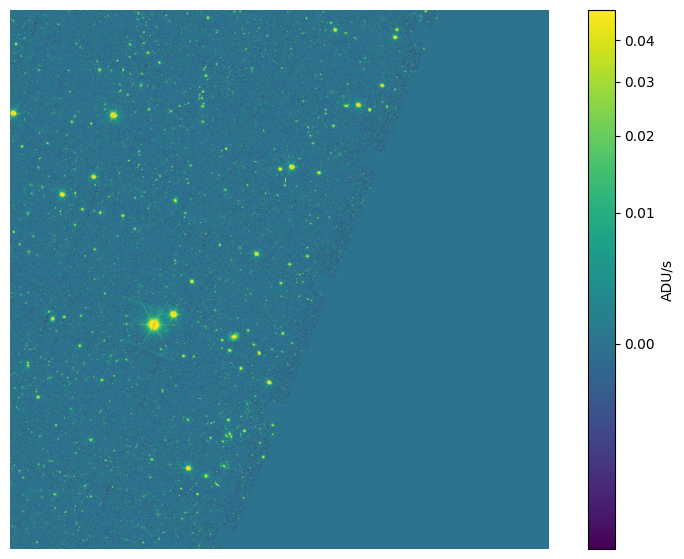

In [8]:
# defining the full path in datalabs
file_path  = res["datalabs_path"][0] + "/" + res["file_name"][0]

plt.figure(figsize = [10,7])

img, head  = utils.plot_image(fits_path=file_path, cbar=True, under_samp=10)

### 1.1.2 Display the cutouts

Associated to the three FITS files listed above: there is one DEEP observation that combines two visits. The title of each panel displays the object_id and the patch_id_list. Note that the DEEP (combined) image contains data from the two individual visits, as reflected in its patch_id_list.

Displaying 3 cutout(s)


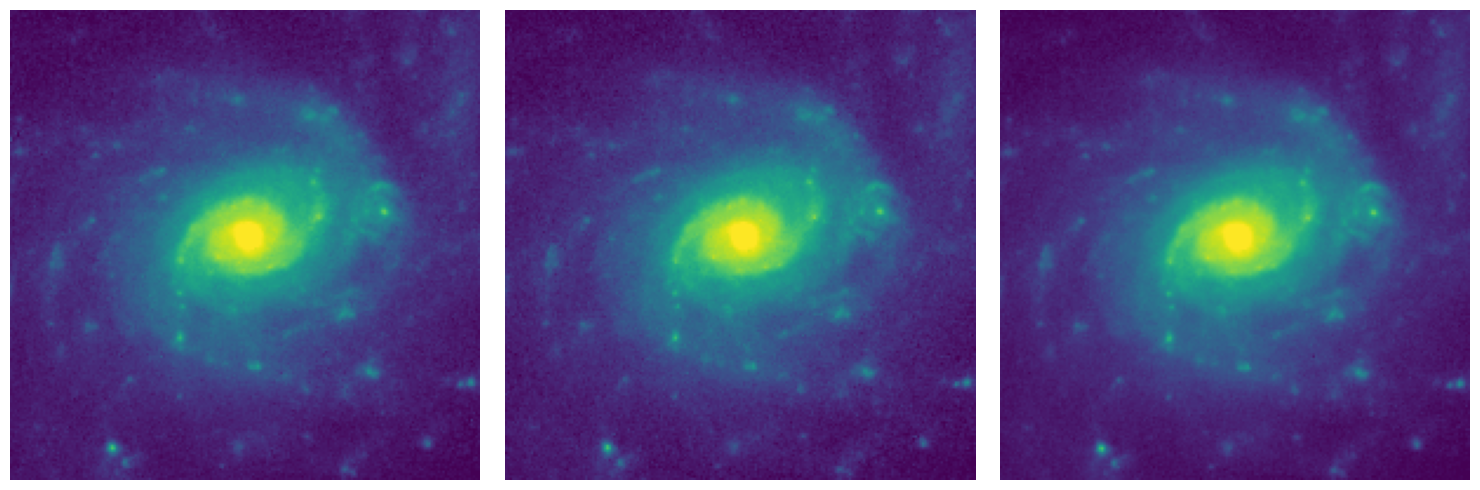

In [9]:
# Cutouts generation ============
cutout_r    = 20 * u.arcsecond # Cutout size (height x weight)
list_cutout = []

for ii in range(len(res)):
    file_path     = f"{res['datalabs_path'][ii]}/{res['file_name'][ii]}"
    hdul          = fits.open(file_path)
    coords_ra     = res['right_ascension'][ii]
    coords_dec    = res['declination'][ii]
    coords        = SkyCoord(coords_ra, coords_dec, unit="deg")
    cutout        = Cutout2D(data=hdul[0].data, position = coords, size= cutout_r, wcs=wcs.WCS(hdul[0].header))
    list_cutout.append(cutout)
    hdul.close()
    
_ = utils.plot_cutouts(list_cutout, figsize=[15,5], n_cols=3, n_rows=1)    

## 1.2 Auxiliary MOSAIC product (cutouts)

To find auxiliary files associated to the mosaic product, it is necessary to JOIN the dr1.mosaic_product to the dr1.aux_mosaic table using their common **"mosaic_product_oid"** field. 


The main target tables for this use case are **dr1.mosaic_product**. and **dr1.aux_mosaic**.

```sql
SELECT <cols>
FROM dr1.mosaic_product 
JOIN dr1.aux_mosaic USING (mosaic_product_oid)
WHERE ....
ORDER BY ... ASC
```

### 1.2.1 Find the AUX files

We focus in obtaining the auxilary files associated to the DEEP image (which in the previous query has associated processing_mode = 'DEEP' and tile_index = 101368211. Because of this, the query targets one MER mosaic (to obtain the associated coordinates) and then JOIN the dr1.mosaic_product and the dr1.aux_mosaic.

In [10]:
tile_index = 101368211
query      = f"""SELECT mer.object_id, mer.right_ascension, mer.declination, mp.first_type, mp.tile_index, mp.instrument_name, mp.observation_id_list, mp.patch_id_list, mp.processing_mode,
            mp.reference_observation_date_time, mp.file_name AS file_name_mosaic, am.product_type_sas, am.stype, am.datalabs_path, am.file_name AS file_name_aux
            FROM {schema}.mer_catalogue_deep_survey AS mer
            JOIN {schema}.mosaic_product AS mp
                ON 1 = INTERSECTS(CIRCLE(mer.right_ascension, mer.declination,1/3600.), mp.fov)
            JOIN {schema}.aux_mosaic AS am USING (mosaic_product_oid)
            WHERE mer.object_id = {object_id}
            AND instrument_name = '{instrument}'
            AND mp.tile_index = {tile_index}
            ORDER BY stype ASC"""

res_aux = utils.get_query_results(Euclid, query=query)

ADQL query: 
SELECT mer.object_id, mer.right_ascension, mer.declination, mp.first_type, mp.tile_index, mp.instrument_name, mp.observation_id_list, mp.patch_id_list, mp.processing_mode,
            mp.reference_observation_date_time, mp.file_name AS file_name_mosaic, am.product_type_sas, am.stype, am.datalabs_path, am.file_name AS file_name_aux
            FROM dr1.mer_catalogue_deep_survey AS mer
            JOIN dr1.mosaic_product AS mp
                ON 1 = INTERSECTS(CIRCLE(mer.right_ascension, mer.declination,1/3600.), mp.fov)
            JOIN dr1.aux_mosaic AS am USING (mosaic_product_oid)
            WHERE mer.object_id = -515026844295568271
            AND instrument_name = 'VIS'
            AND mp.tile_index = 101368211
            ORDER BY stype ASC

INFO: Query finished. [astroquery.utils.tap.core]
Total runtime: 0.8 seconds


object_id,right_ascension,declination,first_type,tile_index,instrument_name,observation_id_list,patch_id_list,processing_mode,reference_observation_date_time,file_name_mosaic,product_type_sas,stype,datalabs_path,file_name_aux
NA,deg,deg,,,,,,,,,,,,
int64,float64,float64,object,int64,object,object,object,object,object,object,object,object,object,object
-515026844295568271,51.50268448673661,-29.55682711146592,STD,101368211,VIS,3017 3057,"58,59",DEEP,2024-08-07T02:28:42.136,EUC_MER_BGSUB-MOSAIC-VIS_TILE101368211-4208E2_20250730T101200.722985Z_00.00.fits,MERBKG,BKG,/data/euclid_idr1/DR1/R2/MER/101368211/VIS,EUC_MER_BGMOD-VIS_TILE101368211-8506E5_20250730T101200.722783Z_00.00.fits
-515026844295568271,51.50268448673661,-29.55682711146592,STD,101368211,VIS,3017 3057,"58,59",DEEP,2024-08-07T02:28:42.136,EUC_MER_BGSUB-MOSAIC-VIS_TILE101368211-4208E2_20250730T101200.722985Z_00.00.fits,MERBRIGHT_STAR_MASKS,BRIGHT_STAR_MASKS,/data/euclid_idr1/DR1/R2/MER/101368211/VIS,EUC_MER_STAR-MASKS-VIS_TILE101368211-FF220C_20250730T092856.887652Z_00.00.json
-515026844295568271,51.50268448673661,-29.55682711146592,STD,101368211,VIS,3017 3057,"58,59",DEEP,2024-08-07T02:28:42.136,EUC_MER_BGSUB-MOSAIC-VIS_TILE101368211-4208E2_20250730T101200.722985Z_00.00.fits,MERFLAG,FLAG,/data/euclid_idr1/DR1/R2/MER/101368211/VIS,EUC_MER_MOSAIC-VIS-FLAG_TILE101368211-FBC026_20250730T092856.887614Z_00.00.fits
-515026844295568271,51.50268448673661,-29.55682711146592,STD,101368211,VIS,3017 3057,"58,59",DEEP,2024-08-07T02:28:42.136,EUC_MER_BGSUB-MOSAIC-VIS_TILE101368211-4208E2_20250730T101200.722985Z_00.00.fits,MERGRID_PSF,GRID_PSF,/data/euclid_idr1/DR1/R2/MER/101368211/VIS,EUC_MER_GRID-PSF-VIS_TILE101368211-7E7CB4_20250730T092856.887628Z_00.00.fits
-515026844295568271,51.50268448673661,-29.55682711146592,STD,101368211,VIS,3017 3057,"58,59",DEEP,2024-08-07T02:28:42.136,EUC_MER_BGSUB-MOSAIC-VIS_TILE101368211-4208E2_20250730T101200.722985Z_00.00.fits,MERLAYERS,LAYERS,/data/euclid_idr1/DR1/R2/MER/101368211/VIS,EUC_MER_DETECTOR-LAYERING-VIS_TILE101368211-257946_20250730T092145.951030Z_00.00.fits
-515026844295568271,51.50268448673661,-29.55682711146592,STD,101368211,VIS,3017 3057,"58,59",DEEP,2024-08-07T02:28:42.136,EUC_MER_BGSUB-MOSAIC-VIS_TILE101368211-4208E2_20250730T101200.722985Z_00.00.fits,MERPSF,PSF,/data/euclid_idr1/DR1/R2/MER/101368211/VIS,EUC_MER_CATALOG-PSF-VIS_TILE101368211-2A1071_20250731T130043.686708Z_00.00.fits
-515026844295568271,51.50268448673661,-29.55682711146592,STD,101368211,VIS,3017 3057,"58,59",DEEP,2024-08-07T02:28:42.136,EUC_MER_BGSUB-MOSAIC-VIS_TILE101368211-4208E2_20250730T101200.722985Z_00.00.fits,MERRMS,RMS,/data/euclid_idr1/DR1/R2/MER/101368211/VIS,EUC_MER_MOSAIC-VIS-RMS_TILE101368211-88F239_20250730T092856.887600Z_00.00.fits


### 1.2.2 Display selected AUX files (cutouts)


There are several auxiliary files. Let's plot the cutouts corresponding to the subtracted background model, the flag data set and the RMS noise data set. Note that the Cutout input coordinates and size are re-used from the previous example (so that the files and auxiliary files can be easily compared).

Reading: /data/euclid_idr1/DR1/R2/MER/101368211/VIS/EUC_MER_BGMOD-VIS_TILE101368211-8506E5_20250730T101200.722783Z_00.00.fits
Reading: /data/euclid_idr1/DR1/R2/MER/101368211/VIS/EUC_MER_MOSAIC-VIS-FLAG_TILE101368211-FBC026_20250730T092856.887614Z_00.00.fits
Reading: /data/euclid_idr1/DR1/R2/MER/101368211/VIS/EUC_MER_MOSAIC-VIS-RMS_TILE101368211-88F239_20250730T092856.887600Z_00.00.fits
Displaying 3 cutout(s)


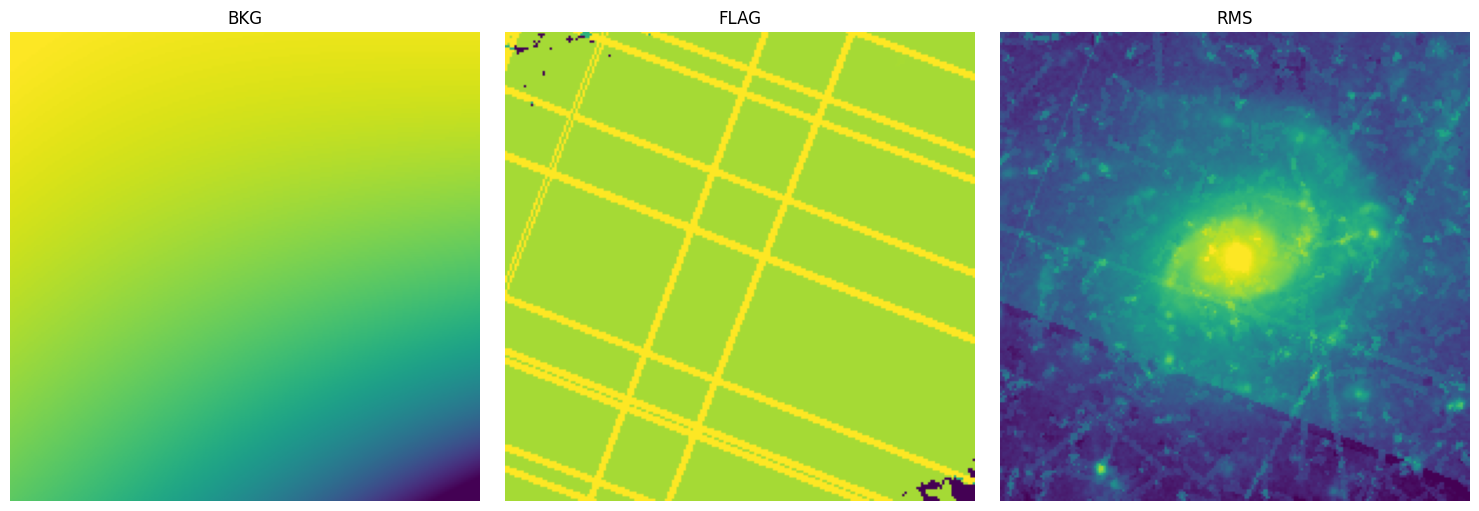

In [11]:
# Selecting the auxiliary FITS files that can be verified with cutouts:
list_cutout_aux = []
list_stype      = ['BKG', 'FLAG', 'RMS']       
for stype in list_stype:
    subset        = res_aux[res_aux['stype'] == stype]
    file_path     = f"{subset['datalabs_path'][0]}/{subset['file_name_aux'][0]}"
    print(f'Reading: {file_path}')
    hdul          = fits.open(file_path)
    cutout        = Cutout2D(data=hdul[0].data, position = coords, size= cutout_r, wcs=wcs.WCS(hdul[0].header))
    list_cutout_aux.append(cutout)
    hdul.close()

_ = utils.plot_cutouts(list_cutout_aux, figsize=[15,5], n_cols=3, n_rows=1, titles=list_stype)    

# 2. STACKED images (cutouts)

Find the stacked images associated to the same object. As in the previous example, this use case applies an [INTERSECTS](https://www.ivoa.net/Documents/ADQL/20231215/REC-ADQL-2.1.html#tth_sEc4.2.17) clause. Note that, in the example below, two stacked images are found.
The main target table for this use case is **dr1.observation_stack**. An example query could be:

```sql
SELECT <cols>, DISTANCE(<target_ra>, <target_dec>, ra, dec) AS dist
FROM <target_mer_catalogue>
JOIN dr1.observation_stack ...
  ON 1=INTERSECTS(CIRCLE(<target_ra>, <target_dec>, <radius>), fov)
WHERE ...
ORDER BY ... ASC
```

## 2.1 Find the STACKED images

The footprint of each observation (.FITS file) is included the "observation_stack.fov" field.

In [12]:
filter_name = 'VIS'
query      = f"""SELECT mer.object_id, mer.right_ascension, mer.declination, mer.tile_index,os.*, DISTANCE(mer.right_ascension, mer.declination, os.ra, os.dec) AS dist
            FROM {schema}.mer_catalogue_deep_survey AS mer
            JOIN {schema}.observation_stack AS os
                ON 1 = INTERSECTS(CIRCLE(mer.right_ascension, mer.declination,2/3600.), os.fov)
            WHERE mer.object_id = {object_id}
            AND filter_name = '{filter_name}'"""
res = utils.get_query_results(Euclid, query=query)

ADQL query: 
SELECT mer.object_id, mer.right_ascension, mer.declination, mer.tile_index,os.*, DISTANCE(mer.right_ascension, mer.declination, os.ra, os.dec) AS dist
            FROM dr1.mer_catalogue_deep_survey AS mer
            JOIN dr1.observation_stack AS os
                ON 1 = INTERSECTS(CIRCLE(mer.right_ascension, mer.declination,2/3600.), os.fov)
            WHERE mer.object_id = -515026844295568271
            AND filter_name = 'VIS'

INFO: Query finished. [astroquery.utils.tap.core]
Total runtime: 0.8 seconds


object_id,right_ascension,declination,tile_index,activity_code,category,creation_date,crpix1,crpix2,crval1,crval2,datalabs_path,data_release_oid,data_set_release,dec,duration,environment,file_checksum,file_name,file_path,filter_name,first_type,fov,instrument_name,observation_id,observation_stack_oid,pa,patch_id,product_id,product_type,provenance_id,published,purpose,ra,release_date,release_name,second_type,start_time,stc_s,technique,to_be_published,version,zero_point,zero_point_error,dist
NA,deg,deg,,,,,,,,,,,,deg,,,,,,,,,,,,,,,,,,,deg,,,,,,,,,,,
int64,float64,float64,int64,object,object,object,float64,float64,float64,float64,object,int64,object,float64,float64,object,object,object,object,object,object,object,object,object,int64,float64,int64,object,object,int64,int32,object,float64,object,object,object,object,object,object,int32,int32,float64,float64,float64
-515026844295568271,51.50268448673661,-29.55682711146592,101368211,,SCIENCE,2025-06-07T06:23:06.573,13136.5,15730.0,51.73028391125,-29.32859728534,/data/euclid_idr1/DR1/R1/VIS/3057,4,DR1_R1,-29.32859728534,2421.12,DR1,14dc74cb4bc961d543e984c35c901cc0,EUC_VIS_SWL-STK-000-000000-0000000__20250607T061920.173575Z.fits,/data/euclid/repository_dr1/DR1/R1/VIS/3057,VIS,OTHER,[51.16013085419565 -29.043443974686898 51.94615476628061 -28.7894614114902\n 52.303978366980175 -29.611346426380994 51.51247752446368\n -29.86741647847266],VIS,3057,9531,--,59,VIS_ProcessField_EUCLID_2.0.52-DATA_RELEASE_DEEP-jbenarro-PLAN-000000-G6H8DCU4-20250605-122148-42-dpdstacked_frame-0,DpdVisStackedFrame,29,0,DATA_RELEASE_DEEP,51.73028391125,,DR1_R1,OTHER,2024-08-08T00:40:16.795,Polygon J2000 51.16013085419566 -29.043443974686895 51.94615476628059 -28.789461411490187 52.30397836698019 -29.61134642638099 51.5124775244637 -29.867416478472652,IMAGE,1,1,23.9,0.02519,0.3022808794062822
-515026844295568271,51.50268448673661,-29.55682711146592,101368211,,SCIENCE,2025-06-06T16:07:50.625,13135.5,15741.5,51.76379808571,-29.33300294628,/data/euclid_idr1/DR1/R1/VIS/3017,4,DR1_R1,-29.33300294628,2421.12,DR1,3e9a7f0f1e5e259328b02c1d0fed91df,EUC_VIS_SWL-STK-000-000000-0000000__20250606T154920.995070Z.fits,/data/euclid/repository_dr1/DR1/R1/VIS/3017,VIS,OTHER,[51.18885863257981 -29.054728471138496 51.970331729941236\n -28.79102441125478 52.341882189880465 -29.608826029682906\n 51.555069378955466 -29.874686158760493],VIS,3017,9507,--,58,VIS_ProcessField_EUCLID_2.0.52-DATA_RELEASE_DEEP-jbenarro-PLAN-000000-P120ZNAJ-20250605-115000-2-dpdstacked_frame-0,DpdVisStackedFrame,29,0,DATA_RELEASE_DEEP,51.76379808571,,DR1_R1,OTHER,2024-08-05T23:23:49.469,Polygon J2000 51.18885863257983 -29.05472847113852 51.97033172994125 -28.791024411254774 52.341882189880494 -29.6088260296829 51.55506937895544 -29.874686158760472,IMAGE,1,1,23.9,0.023,0.31906291712597273


### 2.1.1 Display the full STACKED images

As before, the image below is undersampled by a factor x10 to reduce the execution time of this notebook. Only one of the stacked images is selected.

FITS file: /data/euclid_idr1/DR1/R1/VIS/3057/EUC_VIS_SWL-STK-000-000000-0000000__20250607T061920.173575Z.fits
Note: displaying an image undersampled by a factor of 10 for faster rendering.



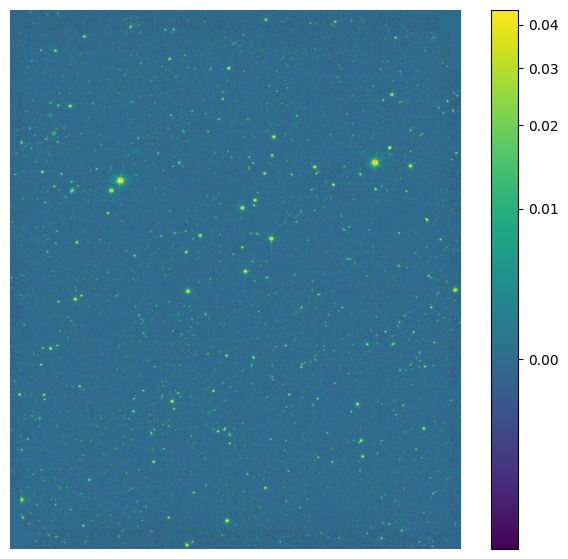

In [13]:
# defining the full path in datalabs
file_path  = res["datalabs_path"][0] + "/" + res["file_name"][0]

plt.figure(figsize = [8,7])

img, head  = utils.plot_image(fits_path=file_path, cbar=True, under_samp=10)

### 2.1.2 Display the cutouts

Associated to the two stacked images obtained above

Displaying 2 cutout(s)


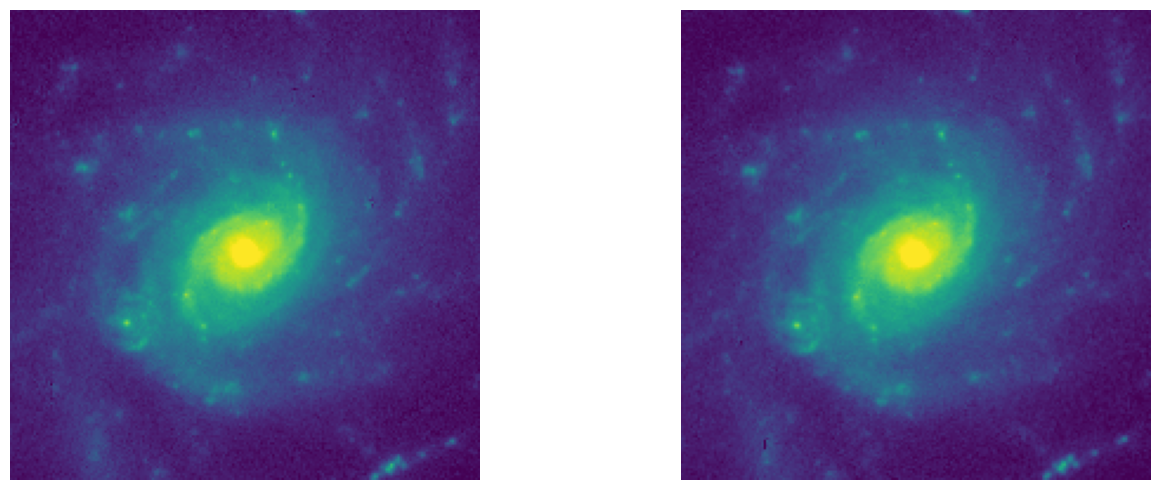

In [14]:
cutout_r    = 20 * u.arcsecond # Cutout size (height x weight)
list_cutout = []

for ii in range(len(res)):
    file_path     = f"{res['datalabs_path'][ii]}/{res['file_name'][ii]}"
    hdul          = fits.open(file_path)
    coords_ra     = res['right_ascension'][ii]
    coords_dec    = res['declination'][ii]
    coords        = SkyCoord(coords_ra, coords_dec, unit="deg")
    cutout        = Cutout2D(data=hdul[0].data, position = coords, size= cutout_r, wcs=wcs.WCS(hdul[0].header))
    list_cutout.append(cutout)
    hdul.close()
    
_ = utils.plot_cutouts(list_cutout, figsize=[15,5], n_cols=2, n_rows=1)    

## 2.2 Auxiliary STACKED product (cutouts)

To find auxiliary files associated to the stacked products, it is necessary to JOIN the dr1.observation_stack to the dr1.aux_stacked table via the common "observation_stack_oid" and "observation_stack_id" fields (see below).



The main target tables for this use case are **dr1.observation_stack**. and **dr1.aux_stacked**.

```sql
SELECT <cols>
FROM dr1.mosaic_product 
JOIN dr1.aux_mosaic USING (mosaic_product_oid)
WHERE ....
ORDER BY ... ASC
```

### 2.2.1 Find the AUX files


There are two types of STACKED auxiliary files: the PSF and WGT files.

In [15]:
tile_index = 101368211
instrument = 'VIS'

query      = f"""SELECT mer.object_id, mer.right_ascension, mer.declination, os.first_type, os.instrument_name, os.observation_stack_oid, os.patch_id, os.start_time, 
            os.file_name AS file_name_stack, ast.product_type_sas, ast.stype, ast.datalabs_path, ast.file_name AS file_name_aux
            FROM {schema}.mer_catalogue_deep_survey AS mer
            JOIN {schema}.observation_stack AS os
                ON 1 = INTERSECTS(CIRCLE(mer.right_ascension, mer.declination,1/3600.), os.fov)
            JOIN {schema}.aux_stacked AS ast
                ON os.observation_stack_oid = ast.observation_stack_id
            WHERE mer.object_id = {object_id}
            AND os.instrument_name = '{instrument}'
            AND mer.tile_index = {tile_index}
            ORDER BY stype ASC"""


job = Euclid.launch_job_async(query)
res_aux = job.get_results()
res_aux

INFO: Query finished. [astroquery.utils.tap.core]


object_id,right_ascension,declination,first_type,instrument_name,observation_stack_oid,patch_id,start_time,file_name_stack,product_type_sas,stype,datalabs_path,file_name_aux
NA,deg,deg,,,,,,,,,,
int64,float64,float64,object,object,int64,int64,object,object,object,object,object,object
-515026844295568271,51.50268448673661,-29.55682711146592,OTHER,VIS,9507,58,2024-08-05T23:23:49.469,EUC_VIS_SWL-STK-000-000000-0000000__20250606T154920.995070Z.fits,DpdVisStackedFramePSF,PSF,/data/euclid_idr1/DR1/R1/VIS/3017,EUC_VIS_SWL-PSF-000-000000-0000000__20250606T154920.995154Z.fits
-515026844295568271,51.50268448673661,-29.55682711146592,OTHER,VIS,9531,59,2024-08-08T00:40:16.795,EUC_VIS_SWL-STK-000-000000-0000000__20250607T061920.173575Z.fits,DpdVisStackedFramePSF,PSF,/data/euclid_idr1/DR1/R1/VIS/3057,EUC_VIS_SWL-PSF-000-000000-0000000__20250607T061920.173648Z.fits
-515026844295568271,51.50268448673661,-29.55682711146592,OTHER,VIS,9507,58,2024-08-05T23:23:49.469,EUC_VIS_SWL-STK-000-000000-0000000__20250606T154920.995070Z.fits,DpdVisStackedFrameWGT,WGT,/data/euclid_idr1/DR1/R1/VIS/3017,EUC_VIS_SWL-WGT-000-000000-0000000__20250606T154920.995168Z.fits
-515026844295568271,51.50268448673661,-29.55682711146592,OTHER,VIS,9531,59,2024-08-08T00:40:16.795,EUC_VIS_SWL-STK-000-000000-0000000__20250607T061920.173575Z.fits,DpdVisStackedFrameWGT,WGT,/data/euclid_idr1/DR1/R1/VIS/3057,EUC_VIS_SWL-WGT-000-000000-0000000__20250607T061920.173660Z.fits


### 2.2.2 Display selected AUX files (cutouts)


Note that cutouts can only be created for the WGT maps.

Reading: /data/euclid_idr1/DR1/R1/VIS/3017/EUC_VIS_SWL-WGT-000-000000-0000000__20250606T154920.995168Z.fits
Reading: /data/euclid_idr1/DR1/R1/VIS/3057/EUC_VIS_SWL-WGT-000-000000-0000000__20250607T061920.173660Z.fits
Displaying 2 cutout(s)


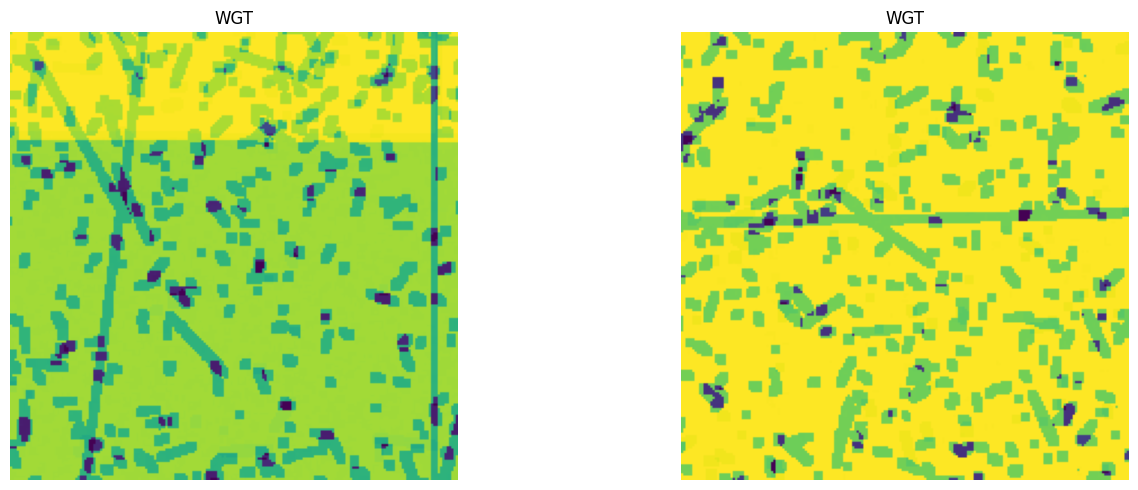

In [16]:
# Selecting the auxiliary FITS files that can be verified with cutouts:
list_cutout_aux = []
subset          = res_aux[res_aux['stype'] == 'WGT']

for row in subset:
    file_path     = f"{row['datalabs_path']}/{row['file_name_aux']}"
    print(f'Reading: {file_path}')
    hdul          = fits.open(file_path)
    cutout        = Cutout2D(data=hdul[0].data, position = coords, size= cutout_r, wcs=wcs.WCS(hdul[0].header))
    list_cutout_aux.append(cutout)
    hdul.close()

_ = utils.plot_cutouts(list_cutout_aux, figsize=[15,5], n_cols=2, n_rows=1, titles=['WGT', 'WGT'])    

Let's have a look at the stack weight of the individual exposures in the cutout region.

# 3. Individual CALIBRATED frames

In the generic example query below, the [INTERSECTS](https://www.ivoa.net/Documents/ADQL/20231215/REC-ADQL-2.1.html#tth_sEc4.2.17) [ADQL](https://www.ivoa.net/Documents/ADQL/20231215/REC-ADQL-2.1.html#) clause combines the target coordinates and the observation footprint (indicated by the "dr1.calibrated_frame.fov" field).

The main target table for this use case is **dr1.calibrated_frame**. An example query could be:

```sql
SELECT <cols>, DISTANCE(<target_ra>, <target_dec>, ra, dec) AS dist
FROM <target_mer_catalogue>
JOIN dr1.calibrated_frame ...
  ON 1=INTERSECTS(CIRCLE(<target_ra>, <target_dec>, <radius>), fov)
WHERE ...
ORDER BY ... ASC
```

## 3.1 Find the Calibrated observations 


In [17]:
filter_name = 'VIS'

query      = f"""SELECT mer.object_id, mer.right_ascension, mer.declination, cf.calibrated_frame_oid, cf.filter_name, cf.datalabs_path, file_name, cf.first_type, 
            cf.instrument_name, cf.observation_id, cf.patch_id, cf.frame_seq, cf.observation_date_time_utc, cf.duration, cf.pointing_id, DISTANCE(mer.right_ascension, mer.declination, cf.ra, cf.dec) AS dist
            FROM {schema}.mer_catalogue_deep_survey AS mer
            JOIN {schema}.calibrated_frame AS cf
                ON 1 = INTERSECTS(CIRCLE(mer.right_ascension, mer.declination,2/3600.), cf.fov)
            WHERE mer.object_id = {object_id}
            AND filter_name = '{filter_name}'
            ORDER BY observation_id, frame_seq ASC"""

job = Euclid.launch_job_async(query)
res = job.get_results()
res

INFO: Query finished. [astroquery.utils.tap.core]


object_id,right_ascension,declination,calibrated_frame_oid,filter_name,datalabs_path,file_name,first_type,instrument_name,observation_id,patch_id,frame_seq,observation_date_time_utc,duration,pointing_id,dist
NA,deg,deg,,,,,,,,,,,,,
int64,float64,float64,int64,object,object,object,object,object,object,int64,int64,object,float64,int64,float64
-515026844295568271,51.50268448673661,-29.55682711146592,16844,VIS,/data/euclid_idr1/DR1/R1/VIS_QUAD/3017,EUC_VIS_SWL-DET-003017-00-2-0000000__20250606T161613.744106Z.fits,SURVEY,VIS,3017,--,0,2024-08-05T23:38:32.471,89.52,13355,0.3573019879462852
-515026844295568271,51.50268448673661,-29.55682711146592,21947,VIS,/data/euclid_idr1/DR1/R1/VIS_QUAD/3017,EUC_VIS_SWL-DET-003017-00-1-0000000__20250606T161417.928569Z.fits,SURVEY,VIS,3017,--,0,2024-08-05T23:23:49.469,560.52,13355,0.3573019879462852
-515026844295568271,51.50268448673661,-29.55682711146592,21948,VIS,/data/euclid_idr1/DR1/R1/VIS_QUAD/3017,EUC_VIS_SWL-DET-003017-01-1-0000000__20250606T161823.032713Z.fits,SURVEY,VIS,3017,--,1,2024-08-05T23:41:35.472,560.52,13356,0.32812119098834597
-515026844295568271,51.50268448673661,-29.55682711146592,21949,VIS,/data/euclid_idr1/DR1/R1/VIS_QUAD/3017,EUC_VIS_SWL-DET-003017-01-2-0000000__20250606T162133.212774Z.fits,SURVEY,VIS,3017,--,1,2024-08-05T23:56:18.474,89.52,13356,0.32812119098834597
-515026844295568271,51.50268448673661,-29.55682711146592,16858,VIS,/data/euclid_idr1/DR1/R1/VIS_QUAD/3017,EUC_VIS_SWL-DET-003017-02-1-0000000__20250606T162250.644646Z.fits,SURVEY,VIS,3017,--,2,2024-08-05T23:59:21.474,560.52,13357,0.31604047495187126
-515026844295568271,51.50268448673661,-29.55682711146592,21794,VIS,/data/euclid_idr1/DR1/R1/VIS_QUAD/3017,EUC_VIS_SWL-DET-003017-03-1-0000000__20250606T161433.635841Z.fits,SURVEY,VIS,3017,--,3,2024-08-06T00:17:07.476,560.52,13358,0.29027119776110566
-515026844295568271,51.50268448673661,-29.55682711146592,21897,VIS,/data/euclid_idr1/DR1/R1/VIS_QUAD/3057,EUC_VIS_SWL-DET-003057-00-1-0000000__20250607T062738.130660Z.fits,SURVEY,VIS,3057,--,0,2024-08-08T00:40:16.795,560.52,13515,0.34337707794001676
-515026844295568271,51.50268448673661,-29.55682711146592,21898,VIS,/data/euclid_idr1/DR1/R1/VIS_QUAD/3057,EUC_VIS_SWL-DET-003057-00-2-0000000__20250607T062834.220560Z.fits,SURVEY,VIS,3057,--,0,2024-08-08T00:54:59.796,89.52,13515,0.34337707794001676


### 3.1.1 Find the HDUs that contain observations of the target


The results show that two observations acquired in different dates ('2024-08-05' and '2024-08-08') were acquired. In the next lines, we focus on the first set of observations (with observation_id = 3017).

The calibrated frames have 432 extensions for the 144 quadrants (4 quadrants for the 36 CCDs) with 3 layers. To extract the image associated to the target object, we need to identify in which HDU the object is located. Note that, in some files, the target source is not found in any of the HDUs.

In [18]:
# Find which HDU contains your source in all calibrated frames
subset  = res[res['observation_id'] == '3017']
goodHDU = np.zeros(len(subset), dtype=int)

for i in range(len(subset)):
    file_path   = f"{subset['datalabs_path'][i]}/{subset['file_name'][i]}"
    coords_ra   = subset['right_ascension'][i]
    coords_dec  = subset['declination'][i]
    coords      = SkyCoord(coords_ra, coords_dec, unit="deg", frame='icrs')

    hdul        = fits.open(file_path)
    
    auxHDU = 0
    for ii in range(len(hdul)):
        try:
            w = WCS(hdul[ii].header)
            if w.has_celestial:
                inside = w.footprint_contains(coords)
                if inside:
                    auxHDU = ii if auxHDU == 0 else auxHDU
        except Exception:
                pass
    if auxHDU == 0:
        print("No HDU found")

    goodHDU[i] = auxHDU

print("Array with found HDU, one per file:", goodHDU)

No HDU found
No HDU found
Array with found HDU, one per file: [289 289   0   0 226 223]


### 3.1.2 Display the cutouts


Reading: /data/euclid_idr1/DR1/R1/VIS_QUAD/3017/EUC_VIS_SWL-DET-003017-00-2-0000000__20250606T161613.744106Z.fits HDU: 289
Reading: /data/euclid_idr1/DR1/R1/VIS_QUAD/3017/EUC_VIS_SWL-DET-003017-00-1-0000000__20250606T161417.928569Z.fits HDU: 289
Reading: /data/euclid_idr1/DR1/R1/VIS_QUAD/3017/EUC_VIS_SWL-DET-003017-02-1-0000000__20250606T162250.644646Z.fits HDU: 226
Reading: /data/euclid_idr1/DR1/R1/VIS_QUAD/3017/EUC_VIS_SWL-DET-003017-03-1-0000000__20250606T161433.635841Z.fits HDU: 223
Displaying 4 cutout(s)


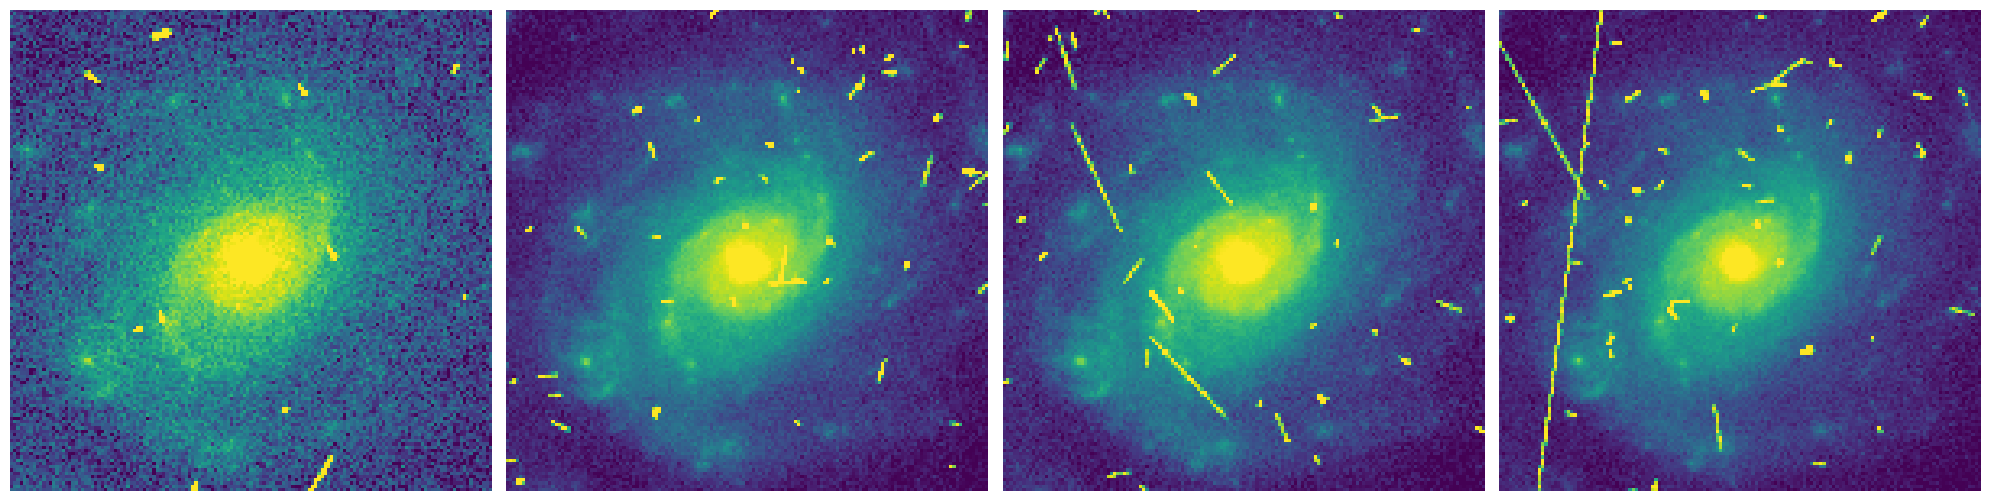

In [19]:
# Cutouts generation ============
cutout_r    = 15 * u.arcsec # Cutout size (height x weight)
cutout_list = []

for ii in range(len(subset)):
    if goodHDU[ii] == 0:
        continue
    file_path     = f"{subset['datalabs_path'][ii]}/{subset['file_name'][ii]}"
    print(f'Reading: {file_path}', 'HDU:', goodHDU[ii])
    hdul          = fits.open(file_path)
    cutout        = Cutout2D(data=hdul[goodHDU[ii]].data, position = coords, size= cutout_r, wcs=wcs.WCS(hdul[goodHDU[ii]].header))
    cutout_list.append(cutout)
    hdul.close()
    
_ = utils.plot_cutouts(cutout_list, figsize=[20,10], n_cols=4, n_rows=1, norm_pc=97.5)

## 3.2 Auxiliary CALIBRATED frames

To find auxiliary files associated to the mosaic product, it is necessary to JOIN the dr1.calibrated_frame to the dr1.aux_calibrated table. For that, we must use the "calibrated_frame_oid" common field.

Note that in the example below, the data associated to observation_id = 3017 and calibrated_frame_oid = 21947 is selected.

In [20]:
observation_id = '3017'
filter_name    = 'VIS'
calibrated_frame_oid = 21947

query      = f"""SELECT mer.object_id, mer.right_ascension, mer.declination, cf.calibrated_frame_oid, cf.filter_name, cf.datalabs_path, cf.file_name AS file_name_frame, 
            cf.first_type, cf.instrument_name, cf.observation_id, cf.patch_id, cf.observation_date_time_utc, ac.product_type_sas, ac.stype, ac.file_name AS file_name_aux
            FROM {schema}.mer_catalogue_deep_survey AS mer
            JOIN {schema}.calibrated_frame AS cf
                ON 1 = INTERSECTS(CIRCLE(mer.right_ascension, mer.declination,1/3600.), cf.fov)
            JOIN {schema}.aux_calibrated AS ac
                ON cf.calibrated_frame_oid = ac.calibrated_frame_id
            WHERE mer.object_id = {object_id}
            AND cf.filter_name = '{filter_name}'
            AND cf.observation_id = '{observation_id}'
            AND cf.calibrated_frame_oid = {calibrated_frame_oid}
            ORDER BY cf.stype ASC"""


job = Euclid.launch_job_async(query)
res_aux = job.get_results()
res_aux

INFO: Query finished. [astroquery.utils.tap.core]


object_id,right_ascension,declination,calibrated_frame_oid,filter_name,datalabs_path,file_name_frame,first_type,instrument_name,observation_id,patch_id,observation_date_time_utc,product_type_sas,stype,file_name_aux
NA,deg,deg,,,,,,,,,,,,
int64,float64,float64,int64,object,object,object,object,object,object,int64,object,object,object,object
-515026844295568271,51.50268448673661,-29.55682711146592,21947,VIS,/data/euclid_idr1/DR1/R1/VIS_QUAD/3017,EUC_VIS_SWL-DET-003017-00-1-0000000__20250606T161417.928569Z.fits,SURVEY,VIS,3017,--,2024-08-05T23:23:49.469,DpdVisCalibratedQuadFrameWGT,WGT,EUC_VIS_SWL-WGT-003017-00-1-0000000__20250606T161417.928656Z.fits
-515026844295568271,51.50268448673661,-29.55682711146592,21947,VIS,/data/euclid_idr1/DR1/R1/VIS_QUAD/3017,EUC_VIS_SWL-DET-003017-00-1-0000000__20250606T161417.928569Z.fits,SURVEY,VIS,3017,--,2024-08-05T23:23:49.469,DpdVisCalibratedQuadFrameBKG,BKG,EUC_VIS_SWL-BKG-003017-00-1-0000000__20250606T161417.928648Z.fits
-515026844295568271,51.50268448673661,-29.55682711146592,21947,VIS,/data/euclid_idr1/DR1/R1/VIS_QUAD/3017,EUC_VIS_SWL-DET-003017-00-1-0000000__20250606T161417.928569Z.fits,SURVEY,VIS,3017,--,2024-08-05T23:23:49.469,DpdVisCalibratedQuadFrameQUALITY_PARAMETERS,QUALITY_PARAMETERS,EUC_VIS_QC-SCI-PERI-003017-00-1-0000000__20250606T163958.216946Z.json
-515026844295568271,51.50268448673661,-29.55682711146592,21947,VIS,/data/euclid_idr1/DR1/R1/VIS_QUAD/3017,EUC_VIS_SWL-DET-003017-00-1-0000000__20250606T161417.928569Z.fits,SURVEY,VIS,3017,--,2024-08-05T23:23:49.469,DpdVisCalibratedQuadFramePSF MODEL,PSF MODEL,EUC_VIS_GRD-PSF-000-000000-0000000__20240322T192915.424564Z.fits


In [21]:
# Find which HDU contains your source in all calibrated frames
subset = res_aux[
    (res_aux['stype'] == 'BKG') |
    (res_aux['stype'] == 'WGT')
]


goodHDU = np.zeros(len(subset), dtype=int)

for i in range(len(subset)):
    file_path   = f"{subset['datalabs_path'][i]}/{subset['file_name_aux'][i]}"
    coords_ra   = subset['right_ascension'][i]
    coords_dec  = subset['declination'][i]
    coords      = SkyCoord(coords_ra, coords_dec, unit="deg", frame='icrs')

    hdul        = fits.open(file_path)
    
    auxHDU = 0
    for ii in range(len(hdul)):
        try:
            w = WCS(hdul[ii].header)
            if w.has_celestial:
                inside = w.footprint_contains(coords)
                if inside:
                    auxHDU = ii if auxHDU == 0 else auxHDU
        except Exception:
                pass
    if auxHDU == 0:
        print("No HDU found")

    goodHDU[i] = auxHDU

print("Array with found HDU, one per file:", goodHDU)

Array with found HDU, one per file: [97 97]


Reading: /data/euclid_idr1/DR1/R1/VIS_QUAD/3017/EUC_VIS_SWL-WGT-003017-00-1-0000000__20250606T161417.928656Z.fits HDU: 97
Reading: /data/euclid_idr1/DR1/R1/VIS_QUAD/3017/EUC_VIS_SWL-BKG-003017-00-1-0000000__20250606T161417.928648Z.fits HDU: 97
Displaying 2 cutout(s)


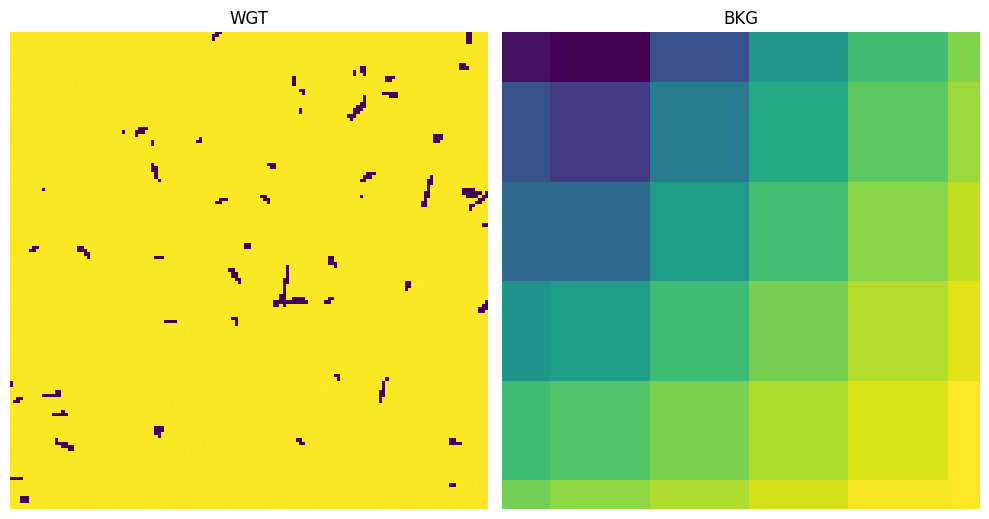

In [22]:
# Cutouts generation ============

cutout_r    = 15 * u.arcsec # Cutout size (height x weight)
cutout_list_aux = []

for ii in range(len(subset)):
    if goodHDU[ii] == 0:
        continue
    file_path     = f"{subset['datalabs_path'][ii]}/{subset['file_name_aux'][ii]}"
    print(f'Reading: {file_path}', 'HDU:', goodHDU[ii])
    hdul          = fits.open(file_path)
    cutout        = Cutout2D(data=hdul[goodHDU[ii]].data, position = coords, size= cutout_r, wcs=wcs.WCS(hdul[goodHDU[ii]].header))
    cutout_list_aux.append(cutout)
    hdul.close()
  
    
_ = utils.plot_cutouts(cutout_list_aux, figsize=[10,10], n_cols=2, n_rows=1, norm_pc=97.5, titles=['WGT','BKG'])

Note that cutouts can only be created for the WGT ans BKG maps.